#**Dataset: 50 Startups**
##About this dataset:
This dataset has data collected from New York, California and Florida about 50 business Startups "17 in each state". The variables used in the dataset are Profit, R&D spending, Administration Spending, and Marketing Spending.

##Dataset Detail:
**Observation:** 50

**response variable(Y):** Profit

**3 predictors (X):**
*   R&D Spend
*   Administration
*   Marketing Spend





#**Load and view data**

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   R&D Spend        50 non-null     float64
 1   Administration   50 non-null     float64
 2   Marketing Spend  50 non-null     float64
 3   State            50 non-null     object 
 4   Profit           50 non-null     float64
dtypes: float64(4), object(1)
memory usage: 2.1+ KB

Missing Value:
R&D Spend          0
Administration     0
Marketing Spend    0
State              0
Profit             0
dtype: int64

Duplicate:
0


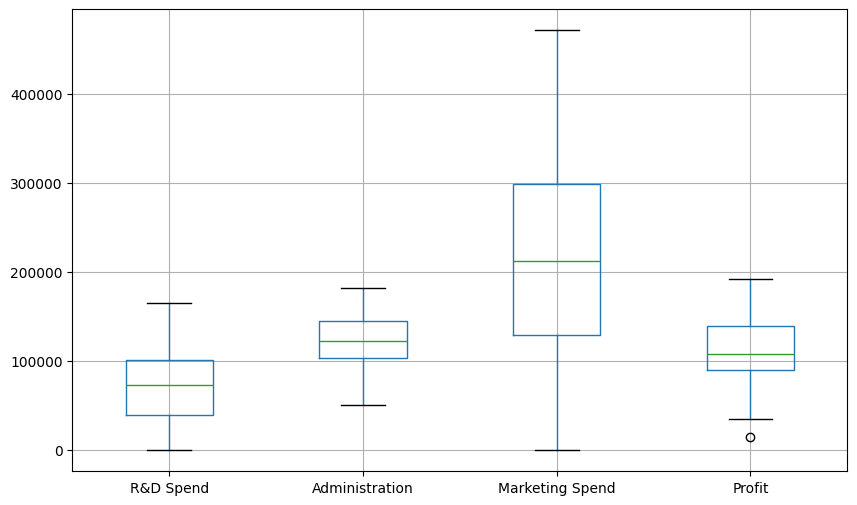

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

#Load data
df = pd.read_csv('50_Startups.csv')
df.head()
df.info()

#Check missing values
print("\nMissing Value:")
print(df.isnull().sum())

#Check duplicate
print("\nDuplicate:")
print(df.duplicated().sum())

#Check Outliers
df.boxplot(figsize=(10,6))
plt.show()

# Encoding since machine learning can not use string to learn
df = pd.get_dummies(df, columns=['State'], drop_first=True)

# Split
X = df.drop('Profit', axis=1)
Y = df['Profit']

# Scaling
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

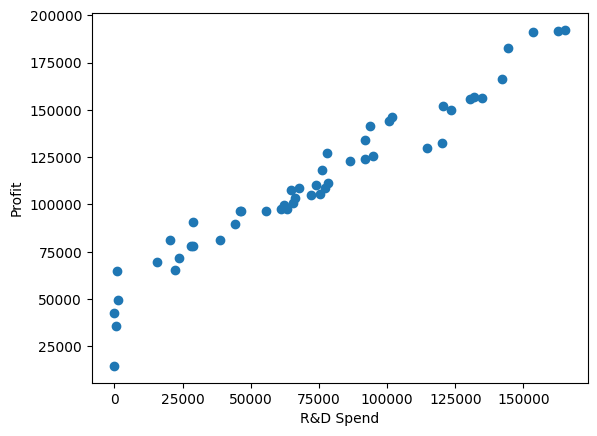

,R&D Spend,Administration,Marketing Spend,Profit,State_Florida,State_New York
49,0.0,116983.8,45173.06,14681.4,False,False


In [ ]:
#Analyze proit outlier
import matplotlib.pyplot as plt

plt.scatter(df['R&D Spend'], df['Profit'])
plt.xlabel('R&D Spend')
plt.ylabel('Profit')
plt.show()
df[df['Profit'] == df['Profit'].min()]

Missing values were checked using isnull().sum(), and no missing values were found in the dataset. Therefore, no imputation was required.

Although there is a low-profit outlier observation, it follows the overall positive relationship between R&D spending and profit. Therefore, it is not considered an outlier and is retained in the dataset.

---

#**Exploratory Data Analysis (EDA)**

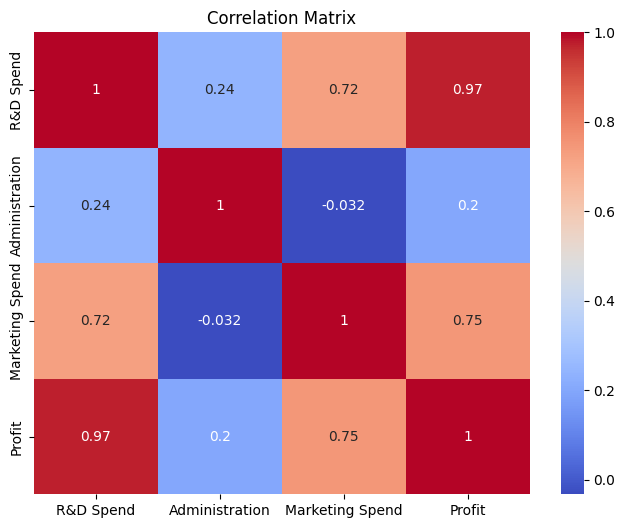

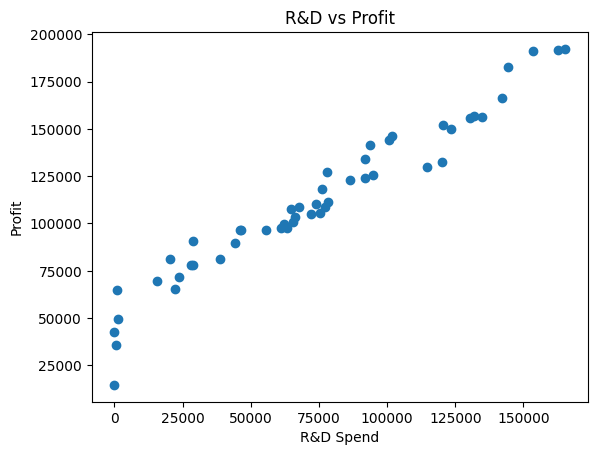

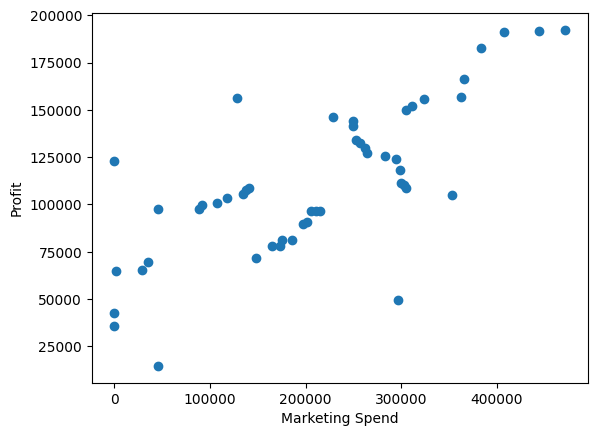

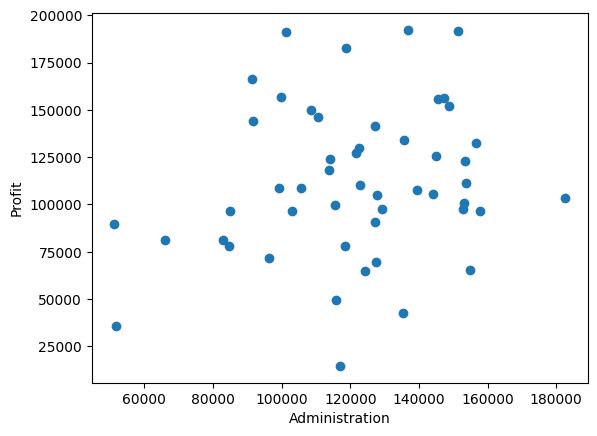


=== Summary Statistics ===
       R&D Spend  Administration  Marketing Spend     Profit
count      50.00           50.00            50.00      50.00
mean    73721.62       121344.64        211025.10  112012.64
std     45902.26        28017.80        122290.31   40306.18
min         0.00        51283.14             0.00   14681.40
25%     39936.37       103730.88        129300.13   90138.90
50%     73051.08       122699.80        212716.24  107978.19
75%    101602.80       144842.18        299469.08  139765.98
max    165349.20       182645.56        471784.10  192261.83


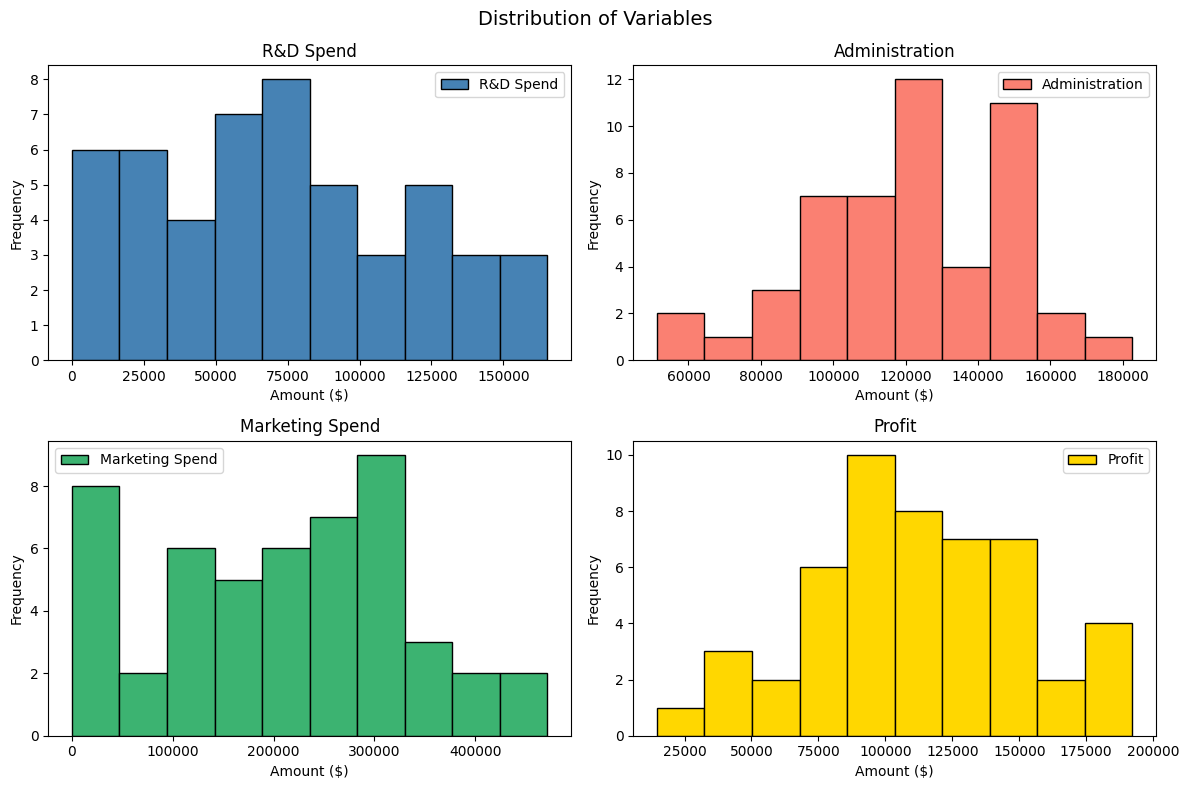

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

df_numeric = df.drop(columns=['State_Florida', 'State_New York'])
corr = df_numeric.corr()

plt.figure(figsize=(8,6))
sns.heatmap(corr, annot=True, cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()

#R&D vs Profit
plt.scatter(df['R&D Spend'], df['Profit'])
plt.xlabel('R&D Spend')
plt.ylabel('Profit')
plt.title('R&D vs Profit')
plt.show()

#Marketing vs Profit
plt.scatter(df['Marketing Spend'], df['Profit'])
plt.xlabel('Marketing Spend')
plt.ylabel('Profit')
plt.show()

#Admin vs Profit
plt.scatter(df['Administration'], df['Profit'])
plt.xlabel('Administration')
plt.ylabel('Profit')
plt.show()

# Summary Statistics
print("\n=== Summary Statistics ===")
df_numeric = df[['R&D Spend', 'Administration', 'Marketing Spend', 'Profit']]
print(df_numeric.describe().round(2))

# Histogram
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
fig.suptitle('Distribution of Variables', fontsize=14)

df[['R&D Spend']].plot(kind='hist', bins=10, ax=axes[0,0], color='steelblue', edgecolor='black')
axes[0,0].set_title('R&D Spend')
axes[0,0].set_xlabel('Amount ($)')

df[['Administration']].plot(kind='hist', bins=10, ax=axes[0,1], color='salmon', edgecolor='black')
axes[0,1].set_title('Administration')
axes[0,1].set_xlabel('Amount ($)')

df[['Marketing Spend']].plot(kind='hist', bins=10, ax=axes[1,0], color='mediumseagreen', edgecolor='black')
axes[1,0].set_title('Marketing Spend')
axes[1,0].set_xlabel('Amount ($)')

df[['Profit']].plot(kind='hist', bins=10, ax=axes[1,1], color='gold', edgecolor='black')
axes[1,1].set_title('Profit')
axes[1,1].set_xlabel('Amount ($)')

plt.tight_layout()
plt.show()



---



#Inference Component
We use **Hypothesis Testing**

**H0:** R&D Spend has no effect on Profit (β1 = 0)

**H1:** R&D Spend has an effect on Profit (β1 ≠ 0)

In [ ]:
import statsmodels.api as sm

X = df[['R&D Spend']]
Y = df['Profit']

X = sm.add_constant(X)

model = sm.OLS(Y, X).fit()
print(model.summary())

# Confidence Interval
print("\n=== 95% Confidence Interval for R&D Spend coefficient ===")
ci = model.conf_int(alpha=0.05)
ci.columns = ['Lower 95%', 'Upper 95%']
print(ci)

print("\nInterpretation:")
lower = ci.loc['R&D Spend', 'Lower 95%']
upper = ci.loc['R&D Spend', 'Upper 95%']
print(f"We are 95% confident that a $1 increase in R&D Spend")
print(f"increases Profit by between ${lower:.4f} and ${upper:.4f}")
print(f"Since the interval does NOT include 0 → Reject H0")

                            OLS Regression Results                            
Dep. Variable:                 Profit   R-squared:                       0.947
Model:                            OLS   Adj. R-squared:                  0.945
Method:                 Least Squares   F-statistic:                     849.8
Date:                Sun, 26 Apr 2026   Prob (F-statistic):           3.50e-32
Time:                        16:40:56   Log-Likelihood:                -527.44
No. Observations:                  50   AIC:                             1059.
Df Residuals:                      48   BIC:                             1063.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       4.903e+04   2537.897     19.320      0.0

A hypothesis test and confidence interval were used to evaluate the significance of R&D Spend.
The p-value is less than 0.05, and the 95% confidence interval does not include zero, confirming that R&D Spend significantly affects Profit.

---



#Modeling Components

                            OLS Regression Results                            
Dep. Variable:                 Profit   R-squared:                       0.947
Model:                            OLS   Adj. R-squared:                  0.945
Method:                 Least Squares   F-statistic:                     849.8
Date:                Sun, 26 Apr 2026   Prob (F-statistic):           3.50e-32
Time:                        16:44:32   Log-Likelihood:                -527.44
No. Observations:                  50   AIC:                             1059.
Df Residuals:                      48   BIC:                             1063.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       4.903e+04   2537.897     19.320      0.0

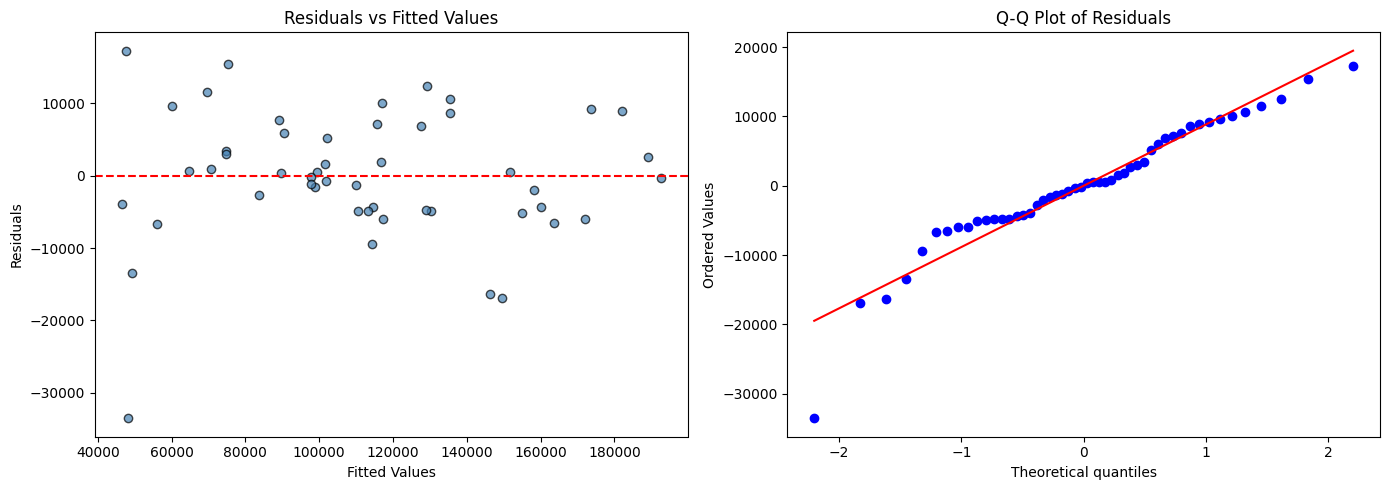

=== Residual Statistics ===
Mean of Residuals : 0.0000
Std of Residuals  : 8945.25
Max Residual      : 17275.43
Min Residual      : -33533.73
=== Model Evaluation Summary ===
Simple Linear Regression:
  R²          = 0.9465
  Adjusted R² = 0.9454

Multiple Linear Regression:
  R²          = 0.9507
  Adjusted R² = 0.9475

Interpretation:
Adjusted R² penalizes adding variables that don't improve the model.
If Adjusted R² of MLR is not much higher than SLR,
the extra variables (Marketing, Administration) add limited value.


In [ ]:
import statsmodels.api as sm

#Simple Linear Regression: Profit = β0 + β1(R&D)
X = df[['R&D Spend']]
Y = df['Profit']

X = sm.add_constant(X)

model_simple = sm.OLS(Y, X).fit()
print(model_simple.summary())

#Multiple Linear Regression: Profit = β0 + β1(R&D) + β2(Marketing) + β3(Admin)
X = df[['R&D Spend', 'Marketing Spend', 'Administration']]
Y = df['Profit']

X = sm.add_constant(X)

model_multiple = sm.OLS(Y, X).fit()
print(model_multiple.summary())

# Residual Analysis
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Residuals vs Fitted Values
fitted = model_multiple.fittedvalues
residuals = model_multiple.resid

axes[0].scatter(fitted, residuals, color='steelblue', edgecolor='black', alpha=0.7)
axes[0].axhline(y=0, color='red', linestyle='--', linewidth=1.5)
axes[0].set_xlabel('Fitted Values')
axes[0].set_ylabel('Residuals')
axes[0].set_title('Residuals vs Fitted Values')

# Plot 2: Q-Q Plot
import scipy.stats as stats
stats.probplot(residuals, dist="norm", plot=axes[1])
axes[1].set_title('Q-Q Plot of Residuals')

plt.tight_layout()
plt.show()

# Residual Stats
print("=== Residual Statistics ===")
print(f"Mean of Residuals : {residuals.mean():.4f}")
print(f"Std of Residuals  : {residuals.std():.2f}")
print(f"Max Residual      : {residuals.max():.2f}")
print(f"Min Residual      : {residuals.min():.2f}")

# Model Comparison Summary
print("=== Model Evaluation Summary ===")
print(f"Simple Linear Regression:")
print(f"  R²          = {model_simple.rsquared:.4f}")
print(f"  Adjusted R² = {model_simple.rsquared_adj:.4f}")
print()
print(f"Multiple Linear Regression:")
print(f"  R²          = {model_multiple.rsquared:.4f}")
print(f"  Adjusted R² = {model_multiple.rsquared_adj:.4f}")
print()
print("Interpretation:")
print("Adjusted R² penalizes adding variables that don't improve the model.")
print("If Adjusted R² of MLR is not much higher than SLR,")
print("the extra variables (Marketing, Administration) add limited value.")

**Simple Linear Regression** R&D Spend has a strong and statistically significant positive effect on Profit (p < 0.05), explaining 94.7% of the variance.

**Multiple Linear Regression** Only R&D Spend is statistically significant, while Marketing and Administration are not. The increase in R² is minimal, indicating limited contribution from additional variables.